In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [3]:
from src.conexao_banco import conn, cursor

- Primeira pergunta de negócio: Quais tipos de veículo apresentam a maior taxa de conclusão?

In [4]:
query = """
    SELECT 
        "Vehicle_Type", 
        COUNT(*) FILTER (WHERE "Booking_Status" = \'Completed\') as quantidade 
    FROM ncr_ride_bookings 
    GROUP BY "Vehicle_Type"
"""

In [5]:
veiculos_corridas = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_23724\3707031635.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  veiculos_corridas = pd.read_sql_query(query, conn)


In [6]:
veiculos_corridas = veiculos_corridas.sort_values(by='quantidade', ascending=False)

In [7]:
veiculos_corridas

,Vehicle_Type,quantidade
0,Auto,22970
3,Go Mini,18404
4,Go Sedan,16550
1,Bike,13921
5,Premier Sedan,11158
2,eBike,6480
6,Uber XL,2765


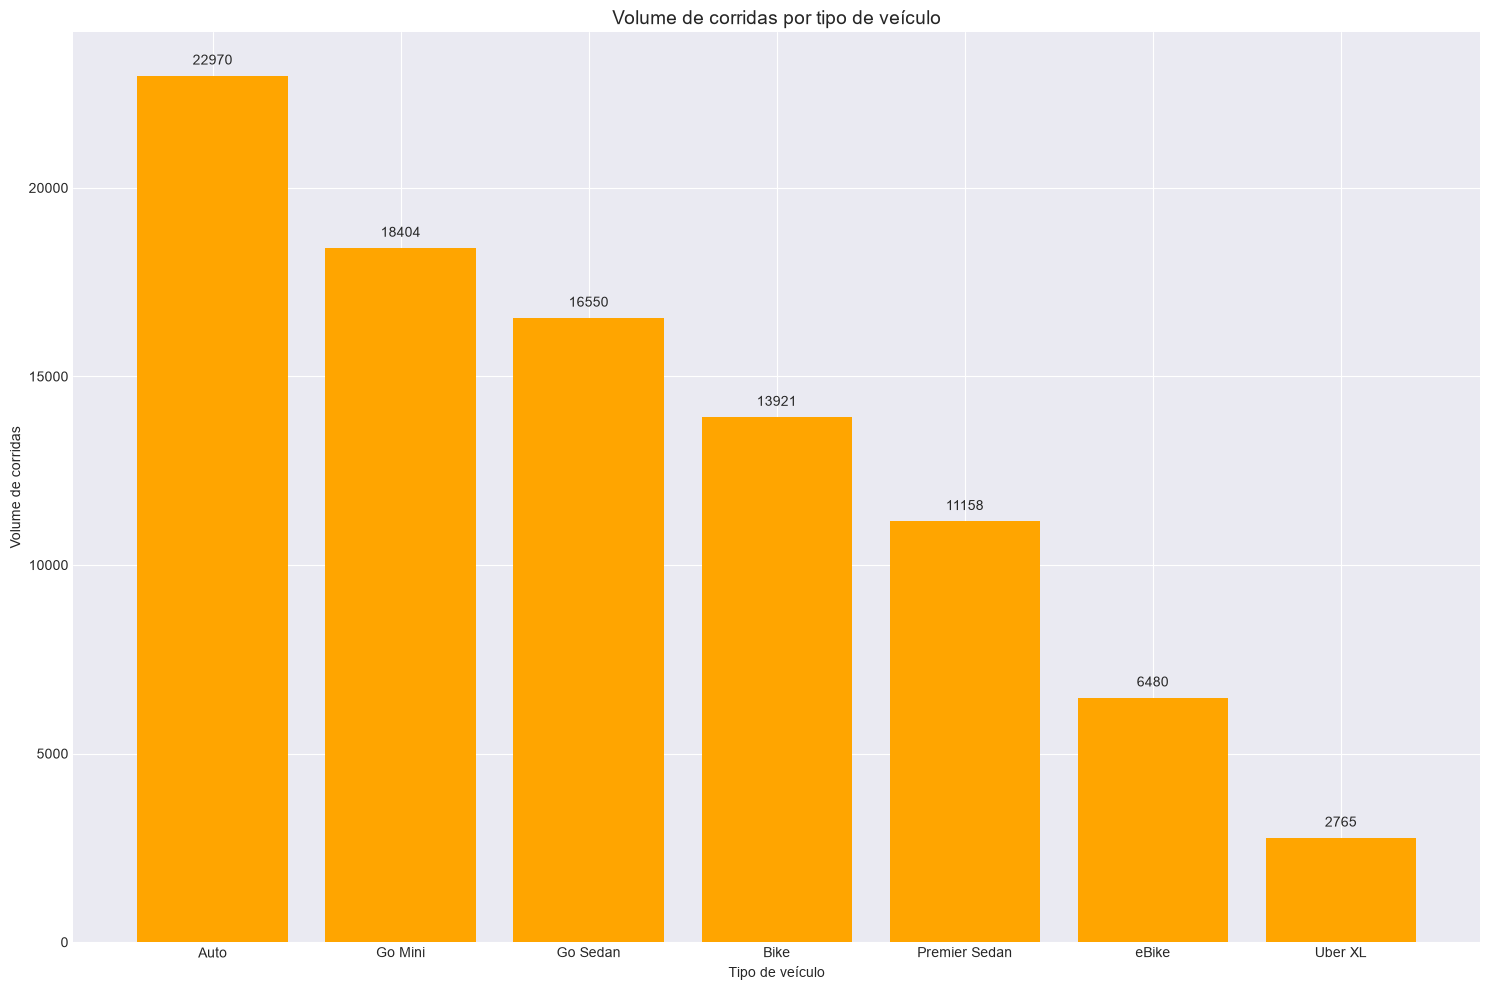

In [ ]:
plt.figure(figsize=(15, 10))
plt.style.use('seaborn-v0_8-darkgrid')

barras = plt.bar(veiculos_corridas['Vehicle_Type'], veiculos_corridas['quantidade'], color='orange')

plt.bar_label(barras, padding=6)

plt.xlabel('Tipo de veículo')
plt.ylabel('Volume de corridas')
plt.title('Volume de corridas por tipo de veículo', fontsize='14')

plt.tight_layout()
plt.show()

    Acima, no gráfico é possível enxergar quais os volumes de corridas por tipo de veículo. Dentre os que detém maiores números estão o Auto com cerca de 22.970 corridas concluídas, Go Mini com cerca de 18.404 corridas concluídas e o Go Sedan com cerca de 16.550 corridas concluídas.

- Segunda pergunta de negócio: Qual tipo de veículo possui o maior valor médio por corrida?

In [9]:
query = """
    SELECT 
        "Vehicle_Type", 
        AVG("Booking_Value") as valor_medio_por_corrida 
    FROM ncr_ride_bookings 
    GROUP BY "Vehicle_Type" 
    ORDER BY AVG("Booking_Value") DESC
"""

In [10]:
valor_medio_veiculos = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_23724\1162519492.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  valor_medio_veiculos = pd.read_sql_query(query, conn)


In [11]:
valor_medio_veiculos

,Vehicle_Type,valor_medio_por_corrida
0,Go Sedan,511.583356
1,Bike,509.745653
2,Premier Sedan,509.698394
3,Go Mini,507.775720
4,Auto,506.791974
5,eBike,503.931908
6,Uber XL,501.645055


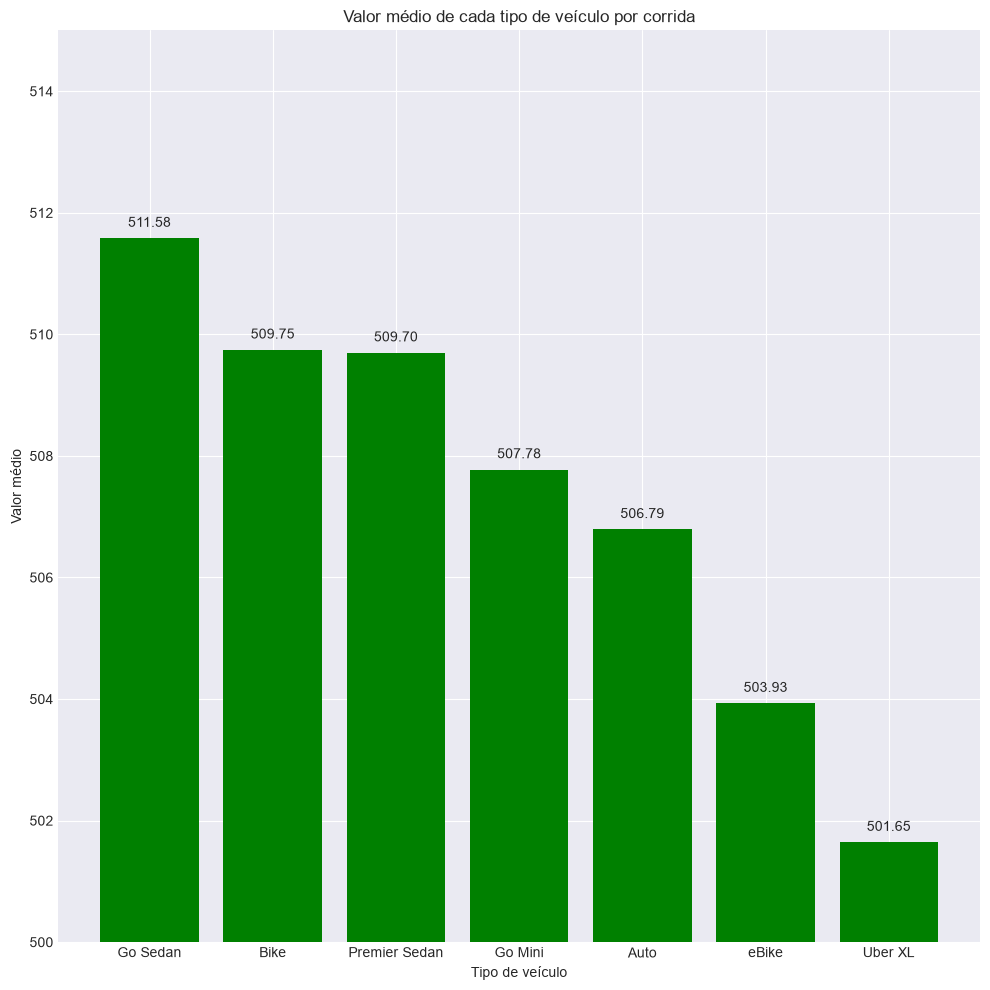

In [12]:
plt.figure(figsize=(10, 10))
plt.style.use('seaborn-v0_8-darkgrid')

barras = plt.bar(valor_medio_veiculos['Vehicle_Type'], valor_medio_veiculos['valor_medio_por_corrida'], color='green')

plt.bar_label(barras, padding=6, fmt='%.2f')

plt.xlabel('Tipo de veículo')
plt.ylim(500, 515)
plt.ylabel('Valor médio')
plt.title('Valor médio de cada tipo de veículo por corrida')

plt.tight_layout()
plt.show()

    Dentre todos os tipos de veículos presentes, o GoSedan é o que apresenta o melhor valor médio por corrida, sendo ele de 511,58 em média.

- Terceira pergunta de negócio: Quais tipos de veículo apresentam a maior distância média por corrida concluída?

In [13]:
query = """
    SELECT 
        "Vehicle_Type", 
        AVG("Ride_Distance") as average_distance 
    FROM ncr_ride_bookings 
    WHERE "Booking_Status" = \'Completed\' 
    GROUP BY "Vehicle_Type"  \
    ORDER BY AVG("Ride_Distance") DESC
"""

In [14]:
distancia_media_veiculo = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_23724\2321670059.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  distancia_media_veiculo = pd.read_sql_query(query, conn)


In [15]:
distancia_media_veiculo

,Vehicle_Type,average_distance
0,eBike,26.344593
1,Bike,25.998178
2,Auto,25.991699
3,Go Sedan,25.984345
4,Go Mini,25.983068
5,Premier Sedan,25.972706
6,Uber XL,25.744709


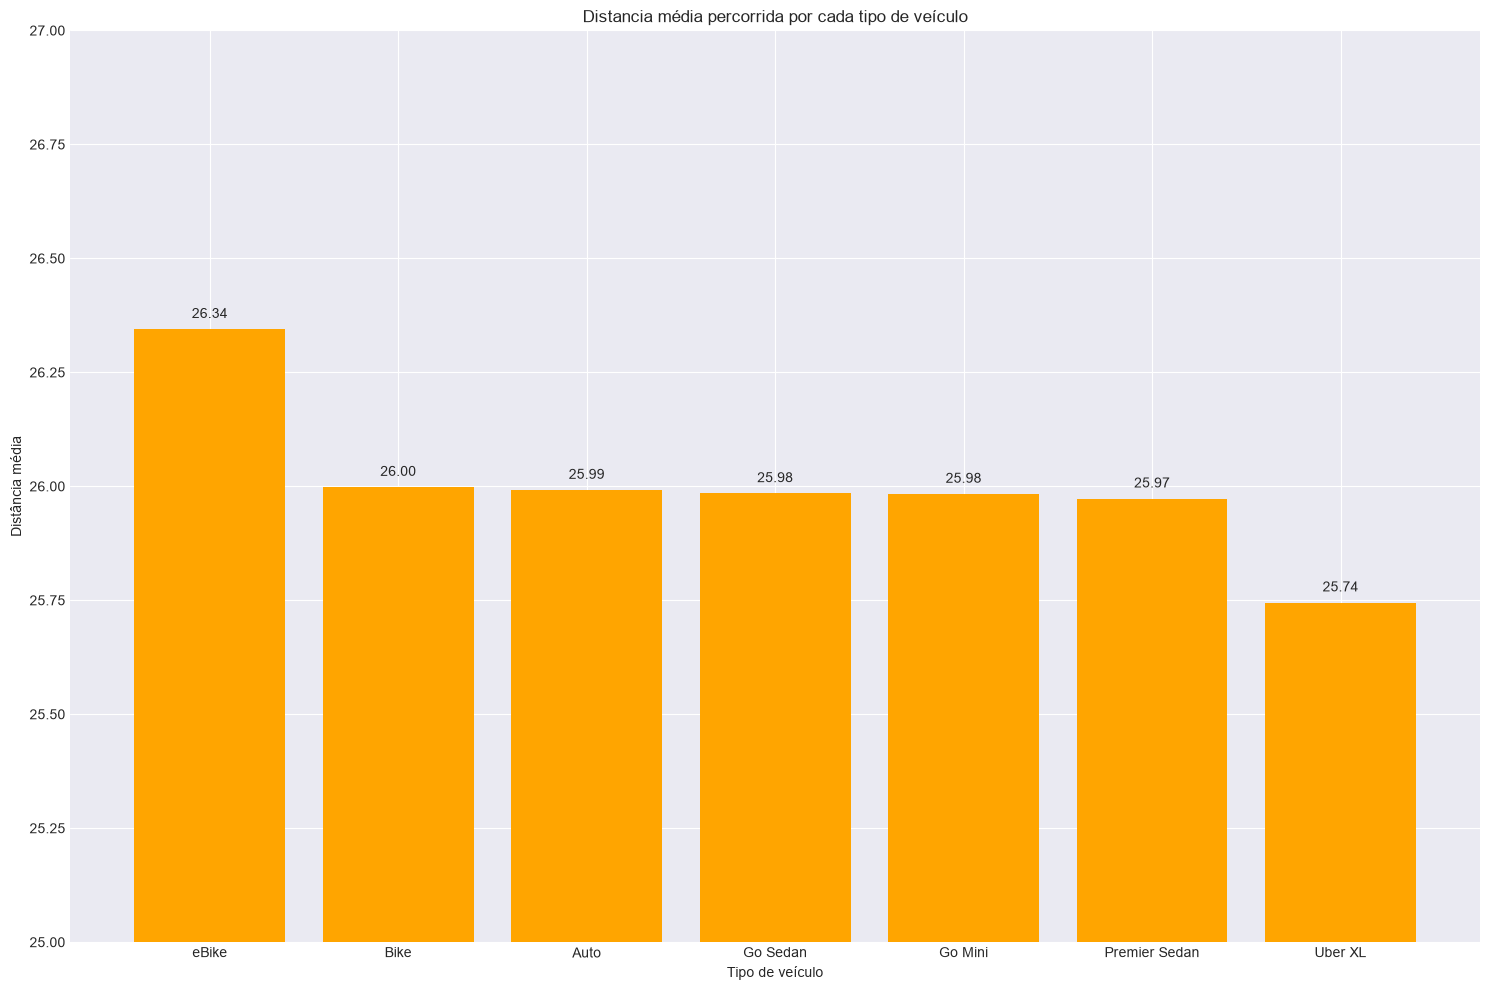

In [16]:
plt.figure(figsize=(15, 10))
plt.style.use('seaborn-v0_8-darkgrid')

barras = plt.bar(distancia_media_veiculo['Vehicle_Type'], distancia_media_veiculo['average_distance'], color='Orange')

plt.bar_label(barras, padding=6, fmt='%.2f')

plt.title('Distancia média percorrida por cada tipo de veículo')
plt.ylim(25, 27)
plt.xlabel('Tipo de veículo')
plt.ylabel('Distância média')

plt.tight_layout()
plt.show()

    Todos os tipos de veículos apresentam distâncias médias percorridas semelhantes. No entanto, a categoria eBike se destaca por registrar a maior média, com 26,34 km percorridos. Em seguida, aparecem as categorias Bike e Auto, com uma distância média de 25,99 km